# IND320 Assignment 3

## Introduction

This is a Jupyter Notebook for the third part of the IND320 - Data to Decision Project Work. This notebook includes:

* Links to Github repository and Streamlit app
* Description of AI Usage
* Open-Meteo weather data for NVE areas, SPC and LOF outlier detection, STL, a spectrogram, and locations saved for the app.

### Video and Links to Github and Streamlit

Github: https://github.com/MagnusFrantsen/IND320-MagnusFrantsen  
Streamlit: https://ind320-magnusfrantsen.streamlit.app/

The video is uploaded to the Github Repository as: "IND320_Project_Work_Part_3.mp4"

### Log Describing Compulsory Work

This section contains a log of the workflow with the Jupyter Notebook and Streamlit App:

I continued on the demo branch in the same Github Repository and Streamlit app, to make sure my changes did not affect the feedback for part 2.

My first step was finding the electricity and precipitation areas in NVE Atlas, and I exported the bidding zones and NVE regions as shapefiles. My first NVE_Region export was missing Region Nord, so I added assert statements checking that all areas are included. The API lists four VASS areas, but the data only contains three, so I combined RS and RØ into VASS 1, used RV as VASS 2 and combined RM and RN into VASS 3. The regions are administrative, so they only roughly match the VASS areas.

Then I sampled 1000 random locations in each area. The areas include sea, so I clipped them to land before sampling in UTM33, which spreads the points evenly by area.

For the weather data I created a function that takes a region and a time interval, looks up the locations and downloads hourly ERA5 data from Open-Meteo. Downloading a full year for 1000 locations would exceed the free daily limit, so I merged the points into ERA5 grid cells and used the number of points in each cell as a weight. This reduced NO3 to 230 downloads, taking about 80 minutes. Each location is saved separately, so an interrupted download can continue.

I interpreted the SATV task as applying to temperature, since the name refers to temperature variations. I used the DCT to remove the seasonal variation and found the SPC boundaries from the median and MAD, because these are barely affected by outliers. For LOF I used both time and temperature, so each point is compared with similar times of the year. I then performed STL and created a spectrogram of the reservoir filling. All of these are wrapped in functions that return the plots, and I tested them.

In the Streamlit app I moved the area selector to the sidebar so all pages share it, and added an area number selector because the weather data needs one specific area. Instead of a separate download page, I made the download a hidden part of the app. The load_weather() function uses the full NO3 result where it exists, and otherwise downloads the five grid cells with the most sampled points for the selected area, cached for one day. This is less accurate, but fast enough for an app. The weather analysis is not available for NO, because a national mean would average away regional outliers, so the page shows a message instead.

I added one page with tabs for STL and the spectrogram, and one with tabs for SPC and LOF. Finally I grouped the pages by topic in a top navigation bar and redesigned the home page. I had AI help me with the download design, the functions and the page layout.


### AI Usage

The AI model used during this assignment was Claude Opus 5.5.

Generally, the AI model has suggested code, and most of the code in this assignment was copied from these suggestions and then adapted by me. I have tried to understand each part by asking follow-up questions about what the code does and why it is needed.

More specifically the AI model has been used for:

* Breaking down the task description into concrete steps for both the notebook and the Streamlit app
* Finding the correct layers in NVE Atlas and checking the downloaded shapefiles
* Clipping the areas to land and sampling 1000 random locations in each area
* Creating the Open-Meteo download function, and reducing the number of API calls by merging locations into ERA5 grid cells
* Creating the functions for the DCT filtering, SPC boundaries, LOF, STL and spectrogram, and the tests of these functions
* Explaining concepts such as the Discrete Cosine Transform, robust statistics and the use of st.stop()
* Designing the global area selector and how the weather data is loaded in the Streamlit app
* Debugging errors, and finding that the VASS areas in the data did not match the areas listed by the API
* Restructuring the Streamlit pages, the navigation and the home page, and providing documentation for st.tabs and st.navigation
* Writing a first draft of the work log and this section, which I reviewed and edited

I have personally reviewed, tested and adapted the generated code, and written most of the comments myself, to make sure I understand what the code is actually doing and to get the desired functionality.

# Tasks

## Downloading data from the open-meteo API

In [1]:
# Importing relevant libraries and defining constants for directories to store shapefiles and data.

import time
from pathlib import Path
import pandas as pd
import requests
import geopandas as gpd
import numpy as np
import shapely

# The URL for the Open-Meteo Archive API, which is used to fetch historical weather data.
ARCHIVE_URL = "https://archive-api.open-meteo.com/v1/archive"

# Defining the data directory and shapefile directory paths for storing and accessing shapefiles. 
# Including a cache directory for storing weather data to avoid repeated API calls (downloads are time-demanding)
DATA_DIR = Path("../data")
SHAPE_DIR = DATA_DIR / "shapefiles"
CACHE_DIR = DATA_DIR / "weather_cache"

In [2]:
# Reading shapefiles for bidding zones and NVE regions using GeoPandas,
# specifying the encoding to handle special characters in the shapefile data.
bidding_zones = gpd.read_file(SHAPE_DIR / "Budområder.shp", encoding="utf-8")
nve_regions = gpd.read_file(SHAPE_DIR / "NVE_Region.shp", encoding="utf-8")

# Performing assertions to ensure that the bidding zones and NVE regions contain the expected values.
assert set(bidding_zones["budomr"]) == {"NO 1", "NO 2", "NO 3", "NO 4", "NO 5"}
assert set(nve_regions["REGION"]) == {"RS", "RØ", "RV", "RM", "RN"}

In [3]:
# Mapping to the VASS areas in Magasinstatistikk.
# The regions are administrative, so their borders only roughly match the VASS areas.
REGION_TO_VASS = {"RS": 1, "RØ": 1, "RV": 2, "RM": 3, "RN": 3}

In [4]:
# Fetch Norway without sea surfaces from NVE
LAND_URL = "https://kart.nve.no/enterprise/rest/services/Mapservices/Administrasjon2/MapServer/11/query"
params = {"where": "OBJTYPE <> 'Havflate'", "outFields": "OBJTYPE", "outSR": 4326, "f": "geojson"}

# Fetching the land area data from the NVE MapServer using a GET request with specified parameters, and converting the response to a GeoDataFrame.
response = requests.get(LAND_URL, params=params, timeout=120)
# Checking the response status to ensure that the request was successful, and raising an error if it was not.
response.raise_for_status()
# Converting the JSON response from the NVE MapServer into a GeoDataFrame
land = gpd.GeoDataFrame.from_features(response.json()["features"], crs=4326)

In [5]:
# Check the structure of the DataFrame
print(land.head())
# Print the information about the GeoDataFrame
print(land.info())

                                            geometry      OBJTYPE
0  POLYGON ((19.55022 69.86386, 19.59827 69.87243...  ÅpentOmråde
1  POLYGON ((22.9982 69.70829, 23.02399 69.74867,...  ÅpentOmråde
2  POLYGON ((23.37012 69.7102, 23.36667 69.71816,...  ÅpentOmråde
3  POLYGON ((20.86598 69.80516, 20.8638 69.80539,...  ÅpentOmråde
4  POLYGON ((19.6674 69.71362, 19.66323 69.73837,...  ÅpentOmråde
<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 1259 entries, 0 to 1258
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype   
---  ------    --------------  -----   
 0   geometry  1259 non-null   geometry
 1   OBJTYPE   1259 non-null   str     
dtypes: geometry(1), str(1)
memory usage: 31.6 KB
None


In [6]:
# Printing the numbers of records in land
print(len(land))
# Printing the counts of unique values in the "OBJTYPE" column of the land GeoDataFrame
print(land["OBJTYPE"].value_counts())

1259
OBJTYPE
ÅpentOmråde    756
Skog           429
Innsjø          49
SnøIsbre        25
Name: count, dtype: int64


In [7]:
# Defining constants for the metric coordinate reference system (CRS), the number of samples to be drawn, 
# and the random seed for reproducibility (suggested by AI).
metric_crs = 25833
samples = 1000
seed = 320

# Creating a function to sample areas from the GeoDataFrame
# Input parameters for the areas GeoDataFrame, land GeoDataFrame, the identifier column, and a random number generator.
def sample_areas(areas, land, id_col, rng):

    # Sampling areas from the provided GeoDataFrame based on their intersection with the land area.
    land_union = land.to_crs(metric_crs).geometry.make_valid().union_all()

    # Converting the areas GeoDataFrame to the metric CRS and ensuring that the geometries are valid.
    valid_areas = areas.to_crs(metric_crs).assign(geometry=lambda df: df.geometry.make_valid())

    # Clipping the valid areas to the land union and sampling points from the clipped areas.
    clipped = gpd.clip(valid_areas, land_union, keep_geom_type=True)

    # Sampling points from the clipped areas using the specified random number generator and returning 
    # the sampled points in the WGS 84 coordinate reference system.
    points = clipped.set_index(id_col).sample_points(samples, rng=rng).explode().to_crs(4326)

    # Returning a DataFrame containing the sampled points with their corresponding area identifiers, latitude, and longitude values.
    return pd.DataFrame({"area": points.index, "lat": points.y.values, "lon": points.x.values})

In [8]:
# Setting up a random number generator with the specified seed for reproducibility of the sampling process.
rng = np.random.default_rng(seed)

# Sampling the bidding zones
el_points = sample_areas(bidding_zones, land, "budomr", rng)

# Adding additional columns to the sampled points DataFrame to indicate the type of area (EL for bidding zones)
# Extracting the numeric part of the area identifier for further analysis.
el_points["omrType"] = "EL"
el_points["omrnr"] = el_points["area"].str.extract(r"(\d)", expand=False).astype(int)

# Sampling the NVE regions
vass_points = sample_areas(nve_regions, land, "REGION", rng)
vass_points["omrType"] = "VASS"
vass_points["omrnr"] = vass_points["area"].map(REGION_TO_VASS)

# Combining and saving all the points
points = pd.concat([el_points, vass_points], ignore_index=True)

# Verifying that the number of sampled points per area matches the expected number of samples and 
# that there are exactly 10 unique areas in the combined points DataFrame.
assert (points.groupby("area").size() == samples).all()
assert points["area"].nunique() == 10

## Downloading data from Open-Meteo

In [9]:
# Defining the weather parameters to be fetched from the Open-Meteo Archive API, including temperature, precipitation, snowfall, shortwave radiation, wind speed, and soil moisture.
weather_params = [
    "temperature_2m",          # degrees C
    "precipitation",           # mm, sum over the preceding hour
    "snowfall",                # cm of snow, divide by 7 for mm water equivalent
    "shortwave_radiation",     # W/m2, mean over the preceding hour
    "wind_speed_10m",          # m/s, because wind_speed_unit=ms is set below
    "soil_moisture_0_to_7cm",  # m3/m3
]

# Turning 'NO3', 'NO 3' and 'no3' into the same key.
def normalize_region(region):
    return region.replace(" ", "").upper()

# Defining the grid size in degrees for snapping the sampled points to a grid.
grid_deg = 0.25

# Creating a function to load locations based on the specified region and
# sampled points, snapping the points to a grid, and returning the number of sampled points in each grid cell.
def load_locations(region, points=points):

    # Selecting the points that match the specified region by normalizing the area names and filtering the DataFrame accordingly.
    selected = points[points["area"].str.replace(" ", "").str.upper() == normalize_region(region)]

    # Checking if any points were found for the specified region and raising a ValueError if none were found.
    if selected.empty:
        raise ValueError(f"No points found for area {region!r}")

    # Snapping the selected points to a grid by rounding their latitude and longitude values to the nearest grid degree.
    snapped = selected.assign(
        lat=(selected["lat"] / grid_deg).round() * grid_deg,
        lon=(selected["lon"] / grid_deg).round() * grid_deg,
    )
        # n_points is the number of sampled points in the cell, used as the weight in the mean
    return snapped.groupby(["lat", "lon"]).size().reset_index(name="n_points")

### Response if Limit is Reached

In [10]:
# Creating a function to handle rate limits when making requests to the Open-Meteo Archive API (suggested by AI)
def wait_after_limit(response):
    """Wait out a rate limit. The daily limit has to wait until the next day."""

    # Creating a variable to store the reason for the rate limit from the API response, 
    # Converting it to lowercase for easier comparison.
    reason = response.json().get("reason", "").lower()

    # Checking if the reason for the rate limit indicates that the daily limit has been reached, and raising a RuntimeError if so.
    if "daily" in reason:
        raise RuntimeError(f"Daily limit reached. Run again tomorrow: {reason}")

    # Pausing the execution of the program for a specified duration based on the reason for the rate limit,
    # Waiting for 3600 seconds (1 hour) if the reason contains "hourly", otherwise waiting for 60 seconds (1 minute).
    # (Suggested by AI) This is to ensure that the program does not exceed the API's rate limits and 
    # can continue making requests after the specified wait time.
    time.sleep(3600 if "hourly" in reason else 60)

In [11]:
# Creating a function to fetch weather data for a specific location (latitude and longitude) 
# and time range (start_date to end_date) from the Open-Meteo Archive API.
def fetch_location(lat, lon, start_date, end_date, variables=weather_params, max_tries=5):
    """Download hourly data for one location and return a DataFrame."""

    # Defining the parameters for the API request, including latitude, longitude, start and end dates,
    # the weather variables to be fetched, the model to be used, timezone, wind speed unit, and elevation settings.
    params = {
        "latitude": lat,
        "longitude": lon,
        "start_date": start_date,
        "end_date": end_date,
        "hourly": ",".join(variables),
        "models": "era5",
        "timezone": "UTC",
        "wind_speed_unit": "ms",
        "elevation": "nan",  # use the grid cell's own elevation, no downscaling to the point
    }

    # Attempting to fetch the weather data from the Open-Meteo Archive API for the specified location and time range, 
    # with a maximum number of retries in case of rate limits or other issues.
    for _ in range(max_tries):

        # Creating a GET request to the Open-Meteo Archive API with the specified parameters and a timeout of 120 seconds.
        response = requests.get(ARCHIVE_URL, params=params, timeout=120)

        # Checking the response status code to determine if the request was successful or if a rate limit was encountered.
        if response.status_code == 429:
            # Using the wait_after_limit function to handle rate limits by pausing execution 
            # for a specified duration before retrying the request.
            wait_after_limit(response)
            continue

        # If the request was successful, raising an error if the response status code indicates a failure,
        # and converting the JSON response to a DataFrame with hourly weather data, 
        # including a timestamp column converted to UTC datetime format.
        response.raise_for_status()
        frame = pd.DataFrame(response.json()["hourly"])
        frame["time"] = pd.to_datetime(frame["time"], utc=True)

        # Returning the DataFrame containing the fetched weather data for the specified location and time range.
        return frame

    # Raising a RunetimeError if the maximum number of retries is reached without 
    # successfully fetching the weather data for the specified location.
    raise RuntimeError(f"Gave up on location ({lat}, {lon}) after {max_tries} tries")

In [12]:
# Creating a function to download weather data for all locations in a specified region and time interval.
def download_weather(region, start_date, end_date, variables=weather_params, pause=20):
    """Download all locations in an area for a time interval.

    Each location is saved separately, so an interrupted download resumes where it stopped.
    The pause keeps a full year of data below the free limit of 5000 calls per hour.
    """

    # Loading the locations for the specified region using the load_locations function,
    locations = load_locations(region)
    # Creating a cache directory for storing the downloaded weather data to avoid repeated API calls.
    cache = CACHE_DIR / f"{normalize_region(region)}_{start_date}_{end_date}"
    # Creating the cache directory if it does not already exist, allowing for the storage of weather data files for each location.
    cache.mkdir(parents=True, exist_ok=True)
    # Printing the number of ERA5 grid cells (locations) found for the specified region.
    print(f"{region}: {len(locations)} ERA5 grid cells")

    # Creating a frames list to store the weather data for each location
    frames = []
    # Iterating over the locations to fetch or load the weather data.
    for number, row in enumerate(locations.itertuples(), start=1):

        # Creating a file path for the cached weather data for the current location based on its latitude and longitude.
        path = cache / f"{row.lat}_{row.lon}.csv"
        # Checking if the cached weather data file for the current location already exists. 
        # If it does, the data is loaded from the CSV file; otherwise, the data is fetched from the API and saved to the cache.
        if path.exists():
            frame = pd.read_csv(path, parse_dates=["time"])
        else:
            frame = fetch_location(row.lat, row.lon, start_date, end_date, variables)
            frame.to_csv(path, index=False)
            print(f"{number}/{len(locations)} done")
            time.sleep(pause)
        # Adding the latitude, longitude, and number of points for the current location to the DataFrame 
        # and appending it to the frames list.
        frames.append(frame.assign(lat=row.lat, lon=row.lon, n_points=row.n_points))
    # Returning a concatenated DataFrame containing the weather data for all locations in the specified region 
    # and time interval, with the index reset.
    return pd.concat(frames, ignore_index=True)

In [13]:
# Creating a function to compute the hourly mean for the area, weighted by the number of points per cell.
def region_mean(weather, variables=weather_params):
    """Compute the hourly mean for the area, weighted by the number of points per cell."""

    # Extracting the values of the specified weather variables from the weather DataFrame.
    values = weather[variables]

    # Calculating the weighted sum of the weather variable values by multiplying them with the number of points in each grid cell,
    # grouping the results by time, and summing them up to obtain the total weighted sum for each hour.
    weighted_sum = values.mul(weather["n_points"], axis=0).groupby(weather["time"]).sum()
    # Calculating the sum of weights (number of points) for each hour, considering only non-missing values,
    # and grouping the results by time to obtain the total weight sum for each hour.
    weight_sum = values.notna().mul(weather["n_points"], axis=0).groupby(weather["time"]).sum()

    # Returning the hourly mean for the area by dividing the weighted sum of weather variable values 
    # by the total weight sum for each hour.
    return weighted_sum / weight_sum

In [14]:
# Defining N03 as the test location for fetching weather data
# Using the load_locations function to retrieve the first location in the NO3 region.
test_location = load_locations("NO3").iloc[0]

# Trying to fetch weather data for the test location and displaying the summary statistics of the fetched data.
try:
    test_frame = fetch_location(test_location["lat"], test_location["lon"], "2024-01-01", "2024-01-02")
    display(test_frame.describe().T)

# Handling any RuntimeError that may occur during the fetching of weather data for the test location
# Printing the error message to inform the user about the issue, allowing the rest of the notebook 
# to continue executing without interruption.
except RuntimeError as error:
    print(error)

,count,mean,std,min,25%,50%,75%,max
temperature_2m,48.0,1.652083,1.603585,-1.30,0.775,1.500,2.825,4.60
precipitation,48.0,0.012500,0.033422,0.00,0.000,0.000,0.000,0.10
snowfall,48.0,0.005833,0.019552,0.00,0.000,0.000,0.000,0.07
shortwave_radiation,48.0,4.958333,11.232473,0.00,0.000,0.000,0.250,47.00
wind_speed_10m,48.0,11.024375,1.172551,8.78,9.970,11.025,12.115,12.84
soil_moisture_0_to_7cm,48.0,0.000000,0.000000,0.00,0.000,0.000,0.000,0.00


In [15]:
# Downloading weather data for the NO3 region for the year 2024, computing the hourly mean, and saving the results to a CSV file.
no3_2024 = download_weather("NO3", "2024-01-01", "2024-12-31")

# Computing the hourly mean for the NO3 region using the region_mean function and saving the results to a CSV file.
no3_mean = region_mean(no3_2024)
# Saving the computed hourly mean weather data for the NO3 region to a CSV file in the specified data directory.
no3_mean.to_csv(DATA_DIR / "NO3_2024_hourly.csv")
# Displaying the summary statistics of the computed hourly mean weather data for the NO3 region.
no3_mean.describe().T

NO3: 230 ERA5 grid cells


,count,mean,std,min,25%,50%,75%,max
temperature_2m,8784.0,4.563771,7.619016,-16.300400,-0.462900,4.147150,10.348425,24.524000
precipitation,8784.0,0.199195,0.285345,0.000000,0.010100,0.085600,0.278225,3.341900
snowfall,8784.0,0.042961,0.102257,0.000000,0.000000,0.000280,0.034650,1.842120
shortwave_radiation,8784.0,100.039489,158.632280,0.000000,0.000000,4.324500,152.714750,753.959000
wind_speed_10m,8784.0,2.845192,1.120053,0.792910,2.018685,2.610590,3.476030,9.105240
soil_moisture_0_to_7cm,8784.0,0.292289,0.031053,0.160538,0.276093,0.293861,0.313749,0.364479


### Outliers and anomalies

#### Plotting the average precipitation as a function of time

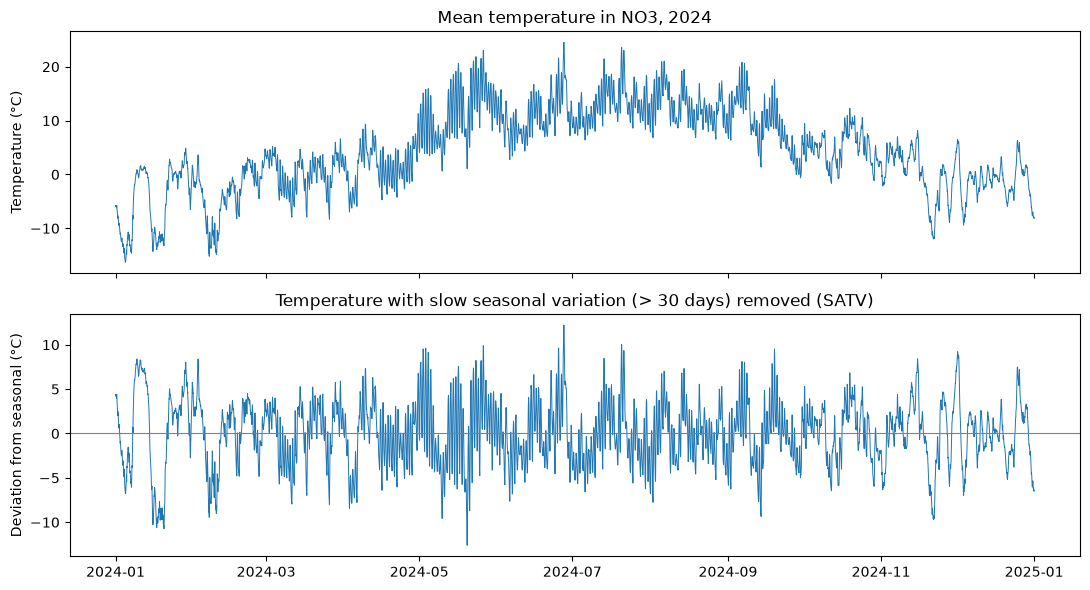

In [16]:
# Importing matplotlib.pyplot for plotting and scipy.fft for performing the Discrete Cosine Transform (DCT) and its inverse (IDCT).
import matplotlib.pyplot as plt
from scipy.fft import dct, idct

# Creating a function to remove slow variations from a time series using the Discrete Cosine Transform (DCT).
def dct_highpass(series, cutoff_days=30):
    """Remove variation slower than cutoff_days using the Discrete Cosine Transform."""

    # If the input series contains any missing values (NaN), 
    # a ValueError is raised to ensure that the DCT can be applied to a complete series without missing data.
    if series.isna().any():
        raise ValueError("The DCT needs a series without missing values")

    # The length of the series is determined, and the DCT coefficients are computed using the 'ortho' normalization.
    n = len(series)
    coefficients = dct(series.to_numpy(), norm="ortho")

    # Coefficient k has a period of 2n / k hours, so slower waves have a lower k
    cutoff = round(2 * n / (cutoff_days * 24))
    coefficients[:cutoff] = 0

    # Returning the inverse DCT of the modified coefficients, which represents 
    # the seasonally adjusted temperature variations (SATV) with a cutoff of 30 days.
    return pd.Series(idct(coefficients, norm="ortho"), index=series.index, name="satv")

# Computing the seasonally adjusted temperature variations (SATV) for the mean temperature in NO3 using the DCT highpass filter with a cutoff of 30 days.
satv = dct_highpass(no3_mean["temperature_2m"])

# Using two panels, because the two series have different baselines
fig, (ax_mean, ax_satv) = plt.subplots(2, 1, figsize=(11, 6), sharex=True)

# Plotting the mean temperature in NO3 for 2024 on the first panel, with a line width of 0.7, and setting the y-axis label and title.
ax_mean.plot(no3_mean.index, no3_mean["temperature_2m"], linewidth=0.7)
ax_mean.set_ylabel("Temperature (°C)")
ax_mean.set_title("Mean temperature in NO3, 2024")

# Plotting the seasonally adjusted temperature variations (SATV) on the second panel, 
# with a line width of 0.7, adding a horizontal line at y=0 for reference, and setting the y-axis label and title.
ax_satv.plot(satv.index, satv, linewidth=0.7)
ax_satv.axhline(0, color="gray", linewidth=0.8)
ax_satv.set_ylabel("Deviation from seasonal (°C)")
ax_satv.set_title("Temperature with slow seasonal variation (> 30 days) removed (SATV)")

# Adjusting the layout of the plots to prevent overlap and ensure that the labels and titles are clearly visible, and displaying the plots.
plt.tight_layout()
# Displaying the plots using plt.show()
plt.show()

In [17]:
# Importing the median_abs_deviation function from scipy.stats to compute the median absolute deviation (MAD)
from scipy.stats import median_abs_deviation

# Creating a function to identify outliers in a time series using Statistical Process Control (SPC) 
# limits based on robust statistics of the seasonally adjusted temperature variations (SATV).
def spc_outliers(series, cutoff_days=30, n_std=3.0, label = "Temperature (°C)", title="Temperature outliers"):
    """Find outliers with SPC limits based on robust statistics of the SATV.

    series: hourly values with a time index.
    cutoff_days: variation slower than this counts as seasonal.
    n_std: number of robust standard deviations from the median to the limits.
    Returns the figure and a dictionary with a summary and a table of the outliers.
    """

    # The seasonally adjusted temperature variations (SATV) are computed using the DCT highpass filter 
    # with the specified cutoff in days.
    satv = dct_highpass(series, cutoff_days)

    # The median and MAD are barely affected by the outliers we are looking for
    center = satv.median()
    robust_std = median_abs_deviation(satv, scale="normal")

    # Adding the seasonal part back gives limits that follow the original series
    seasonal = series - satv
    
    # The lower and upper SPC limits are calculated by adding and subtracting the product of the number 
    # of robust standard deviations (n_std) and the robust standard deviation (robust_std) from the seasonal component and 
    # the center (median) of the SATV.
    lower = seasonal + center - n_std * robust_std
    upper = seasonal + center + n_std * robust_std

    # Identifying outliers based on the SPC limits, where values outside the range defined by the center and robust standard 
    # deviation are considered outliers.
    is_outlier = (satv < center - n_std * robust_std) | (satv > center + n_std * robust_std)
    outliers = pd.DataFrame({"value": series[is_outlier], "satv": satv[is_outlier]})

    # Creating a plot to visualize the original series, SPC limits, and identified outliers.
    fig, ax = plt.subplots(figsize=(11, 4.5))

    # Plotting the original series, SPC limits, and identified outliers on the same axes.
    # Using different colors and line styles for clarity.
    ax.plot(series.index, series, color="#2a78d6", linewidth=0.7, label= label)
    ax.plot(series.index, upper, color="#52514e", linewidth=1, linestyle="--", label="SPC limits")
    ax.plot(series.index, lower, color="#52514e", linewidth=1, linestyle="--")
    # Creating a scatter plot of the identified outliers on top of the original series and SPC limits,
    # using a distinct color and size for better visibility, and adding a label for the outliers in the legend.
    ax.scatter(outliers.index, outliers["value"], color="#eb6834", s=12, zorder=3, label=f"Outliers ({len(outliers)})")
    # Defining the title of the plot to include the number of identified outliers, 
    # the number of robust standard deviations used for the SPC limits, and the cutoff in days for the seasonal adjustment.

    ax.set_title(title)
    # Defining the y-axis label of the plot to display the name of the series or "Value" if the series has no name.
    ax.set_ylabel(label)
    # Adding a grid to the y-axis of the plot with 0.3 transparency level for better readability of the data points and lines.
    ax.grid(axis="y", alpha=0.3)
    # Adding a legend to the plot in the upper right corner without a frame
    ax.legend(loc="upper right", frameon=False)
    # Adjusting the layout of the plot to prevent overlap and ensure that the labels and titles are clearly visible.
    fig.tight_layout()

    """Creating a summary dictionary containing information about the number of outliers, their share in the series,
    the number of high and low outliers, the median of the SATV, the robust standard deviation of the SATV, 
    and a DataFrame containing the identified outliers."""
    summary = {
        "n_outliers": len(outliers),
        "share_outliers": len(outliers) / len(series),
        "n_high": int((outliers["satv"] > center).sum()),
        "n_low": int((outliers["satv"] < center).sum()),
        "satv_median": center,
        "satv_robust_std": robust_std,
        "outliers": outliers,
    }
    # Returning the figure and the summary dictionary
    return fig, summary

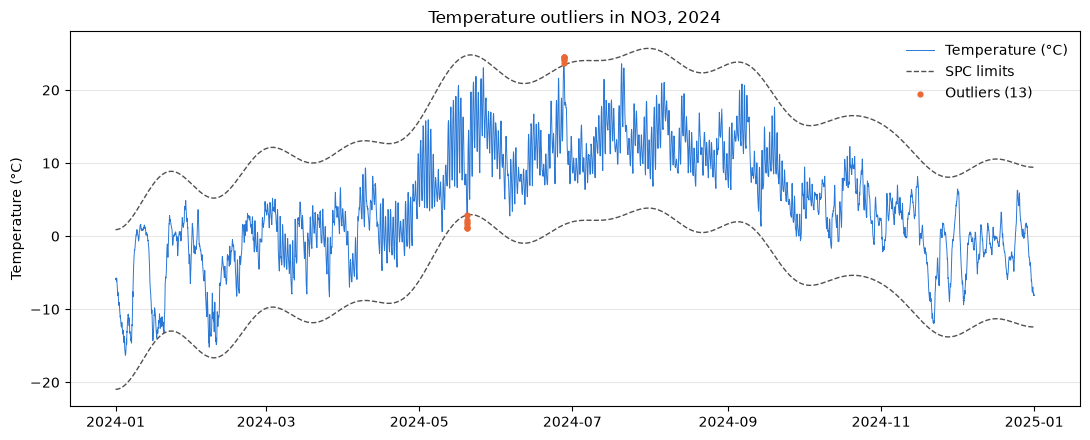

13 outliers: 6 high, 7 low


,value,satv
time,,
2024-05-19 22:00:00+00:00,2.8304,-10.842069
2024-05-19 23:00:00+00:00,2.2010,-11.475156
2024-05-20 00:00:00+00:00,1.6079,-12.071844
2024-05-20 01:00:00+00:00,1.1935,-12.489733
2024-05-20 02:00:00+00:00,1.0779,-12.608724


In [18]:
# Computing the SPC outliers for the mean temperature in NO3 using the spc_outliers function, and displaying the resulting plot.
fig, summary = spc_outliers(no3_mean["temperature_2m"], title="Temperature outliers in NO3, 2024")
plt.show()

# Printing a summary of the number of outliers, including the counts of high and low outliers, and displaying the first few rows 
# of the DataFrame containing the identified outliers.
print(f"{summary['n_outliers']} outliers: {summary['n_high']} high, {summary['n_low']} low")
summary["outliers"].head()

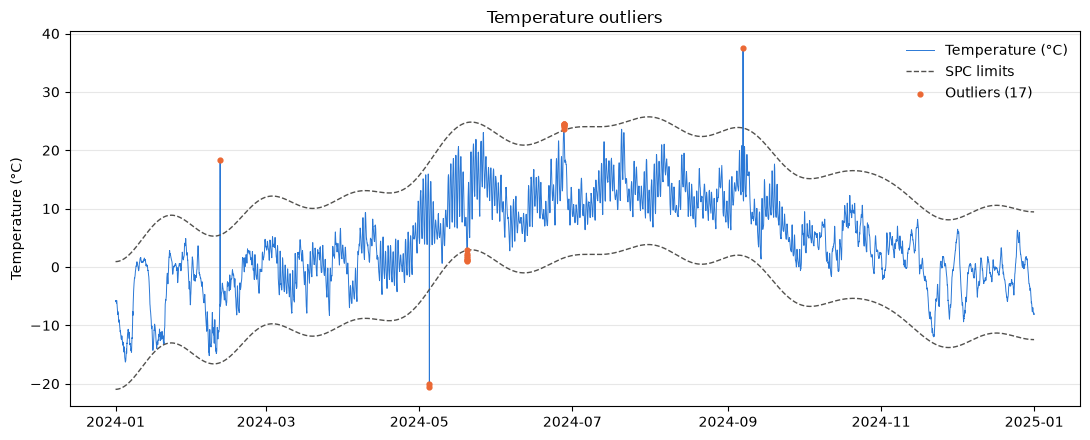

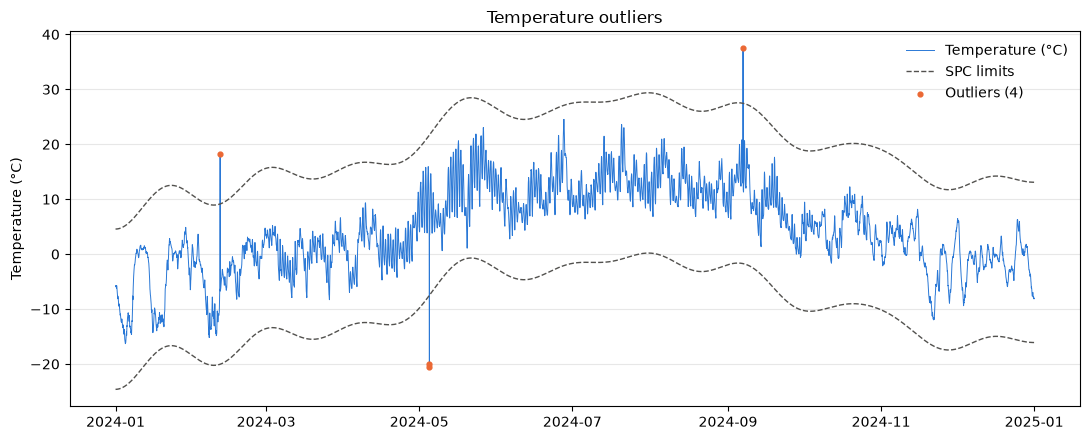

In [19]:
# Testing the spc_outliers function with a modified test series to ensure that it correctly identifies known outliers 
# and behaves as expected with different SPC limits.
test_series = no3_mean["temperature_2m"].copy()
planted = test_series.index[[1000, 3000, 3001, 6000]]
test_series.loc[planted] += [25, -25, -25, 25]

# Running the spc_outliers function on the modified test series and asserting that the known outliers are correctly identified in the output summary.
_, test_summary = spc_outliers(test_series)
assert planted.isin(test_summary["outliers"].index).all()

# Verifying that the number of identified outliers in the test summary 
# is less than or equal to the number of outliers in the original test series
assert spc_outliers(test_series, n_std=4)[1]["n_outliers"] <= test_summary["n_outliers"]

#### Plotting the average temperature as a function of time

In [20]:
# Importing the LocalOutlierFactor class from the sklearn.neighbors module to use for anomaly detection in time series data.
from sklearn.neighbors import LocalOutlierFactor

# Creating a function to find anomalies in a time series using the Local Outlier Factor (LOF) method.
def lof_anomalies(series, proportion=0.01, n_neighbors=20, label="Temperature (°C)", title="Temperature anomalies"):
    """Find anomalies in a time series with the Local Outlier Factor method.

    series: hourly values with a time index.
    proportion: share of the points to mark as anomalies.
    n_neighbors: number of neighbours each point is compared with.
    Returns the figure and a dictionary with a summary and a table of the anomalies.
    """

    # If the input series contains any missing values (NaN)
    # a ValueError is raised to ensure that the LOF method can be applied to a complete series without missing data.
    if series.isna().any():
        raise ValueError("LOF needs a series without missing values")

    # Using time and value, so a point is compared with similar times of the year
    time_position = np.arange(len(series))

    # Creating a feature matrix by stacking the normalized time positions and normalized series values as columns.
    # Used for the Local Outlier Factor (LOF) method to identify anomalies in the time series data.
    features = np.column_stack([
        (time_position - time_position.mean()) / time_position.std(),
        (series - series.mean()) / series.std(),
    ])

    # Creating a LocalOutlierFactor model with the specified number of neighbors and contamination proportion,
    # fitting the model to the feature matrix, and predicting whether each point is an anomaly (-1) or not (1).
    model = LocalOutlierFactor(n_neighbors=n_neighbors, contamination=proportion)
    is_anomaly = model.fit_predict(features) == -1  # -1 marks outliers

    # A score near 1 is normal, and a higher score is more unusual
    scores = pd.Series(-model.negative_outlier_factor_, index=series.index)
    anomalies = pd.DataFrame({"value": series[is_anomaly], "lof_score": scores[is_anomaly]})

    # Creating a plot to visualize the original series and the identified anomalies using the Local Outlier Factor (LOF) method.
    fig, ax = plt.subplots(figsize=(11, 4.5))
    ax.plot(series.index, series, color="#2a78d6", linewidth=0.7, label=label)
    ax.scatter(anomalies.index, anomalies["value"], color="#eb6834", s=12, zorder=3, label=f"Anomalies ({len(anomalies)})")
    ax.set_title(title)
    ax.set_ylabel(label)
    ax.grid(axis="y", alpha=0.3)
    ax.legend(loc="upper right", frameon=False)
    fig.tight_layout()

    # Creating a summary dictionary containing information about the number of anomalies, their share in the series,
    # the minimum and maximum values of the identified anomalies, the number of anomalies per month,
    # and a DataFrame containing the identified anomalies sorted by their LOF scores in descending order
    summary = {
        "n_anomalies": len(anomalies),
        "share_anomalies": len(anomalies) / len(series),
        "value_min": anomalies["value"].min(),
        "value_max": anomalies["value"].max(),
        "anomalies_per_month": anomalies.groupby(anomalies.index.month).size(),
        "anomalies": anomalies.sort_values("lof_score", ascending=False),
    }
    # Returning the figure and the summary dictionary containing information about the identified anomalies in the time series.
    return fig, summary

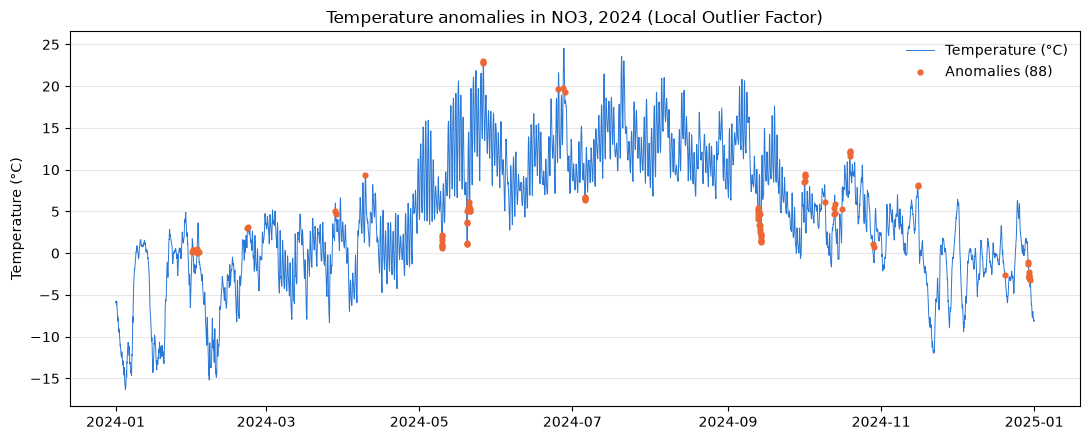

time
1      3
2      5
3      2
4      1
5     22
6      3
7      4
9     18
10    17
11     2
12    11
dtype: int64


,value,lof_score
time,,
2024-10-19 13:00:00+00:00,12.2572,2.595396
2024-10-19 14:00:00+00:00,12.1116,2.409849
2024-12-29 21:00:00+00:00,-2.6637,2.323673
2024-12-30 01:00:00+00:00,-2.8897,2.305951
2024-12-30 00:00:00+00:00,-2.8772,2.295629


In [21]:
# Creating fig and summary variables to store the results of the lof_anomalies function applied to the mean temperature in NO3
fig, summary = lof_anomalies(
    no3_mean["temperature_2m"],
    title="Temperature anomalies in NO3, 2024 (Local Outlier Factor)",
)
# Displaying the plot
plt.show()
# Printing the summary for the anomalies per month
print(summary["anomalies_per_month"])
# Displaying the first rows of the dataframe containing the identified anomalies
summary["anomalies"].head()

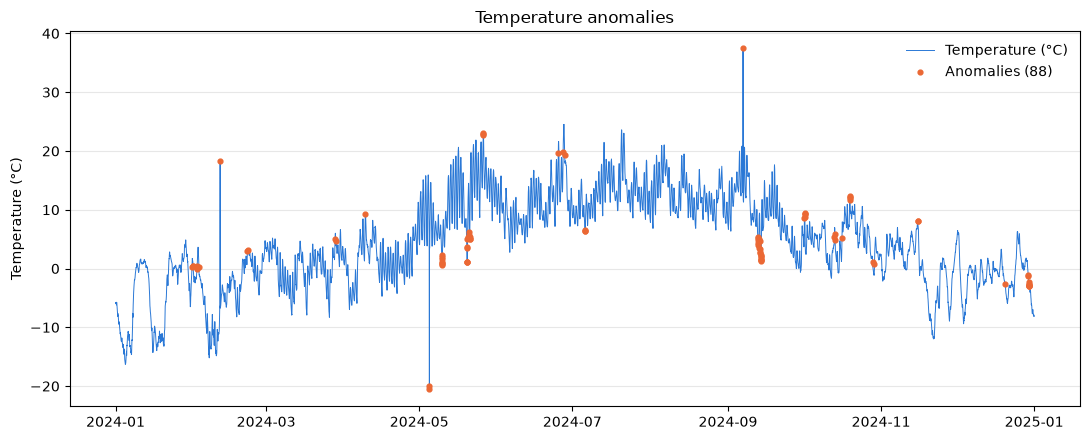

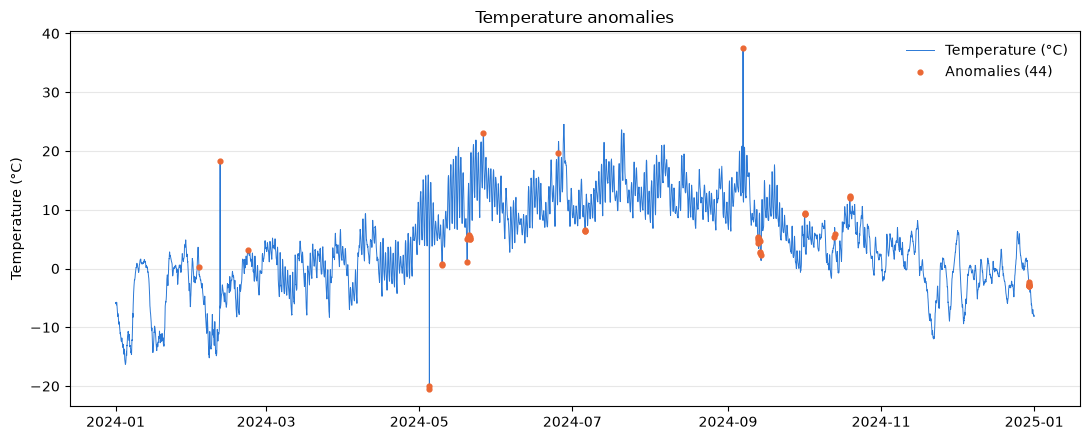

In [22]:
# Creating a test_series by copying the mean temperature in NO3 and modifying specific points to create known anomalies. 
# The modified points are then checked against the output of the lof_anomalies function 
# to ensure that the known anomalies are correctly identified. 
# Additionally, the proportion parameter is tested to verify that it controls the number of points marked as anomalies appropriately.
test_series = no3_mean["temperature_2m"].copy()
planted = test_series.index[[1000, 3000, 3001, 6000]]
test_series.loc[planted] += [25, -25, -25, 25]

# Running the lof_anomalies function on the modified test series and asserting
_, test_summary = lof_anomalies(test_series)
assert planted.isin(test_summary["anomalies"].index).all()

# Verifying that the number of identified anomalies in the test summary 
# is less than or equal to the number of anomalies in the original test series
n_half = lof_anomalies(test_series, proportion=0.005)[1]["n_anomalies"]
assert abs(n_half - 0.005 * len(test_series)) <= 1

#### Seasonal-Trend decomposition using LOESS (STL)

In [23]:
# Importing sys to modify the system path for importing modules from the parent directory.
import sys

# Adding the parent directory to the system path to allow importing the load_data function from utils.py in the repository root.
sys.path.append("..")
# Import load_data from utils.py in the repository roots.
from utils import load_data

# Loading magasin data for the period from January 1900 to December 2100 using the load_data function from utils.py.
# Only retrieving the magasin_data
magasin_data, _, _ = load_data(pd.Period("1900-01", "M"), pd.Period("2100-12", "M"))

2026-11-10 17:29:59.096 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager
2026-11-10 17:29:59.102 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager
2026-11-10 17:29:59.107 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager
2026-11-10 17:29:59.109 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


In [24]:
# Importing the spectrogram function from scipy.signal to compute the spectrogram of a time series,
# and the STL class from statsmodels.tsa.seasonal to perform seasonal-trend decomposition
from scipy.signal import spectrogram
from statsmodels.tsa.seasonal import STL

# Creating filling_series function to return the weekly degree of filling in percent 
# for one area based on the provided magasin data.
def filling_series(data, omr_type="NO", omr_nr=0):
    """Return the weekly degree of filling in percent for one area."""

    # Selecting the rows from the magasin data that match the specified area type and area number.
    selected = data[(data["area_type"] == omr_type) & (data["area_nr"] == omr_nr)]

    # Setting the index of the selected DataFrame to the "Date" column (converted to datetime format) and
    # extracting the "res_level" column, which represents the degree of filling in percent.
    series = selected.set_index(pd.to_datetime(selected["Date"]))["res_level"].sort_index() * 100

    # Filling any missing weeks in the series by resampling it to a weekly frequency ("7D") and interpolating the missing values.
    return series.asfreq("7D").interpolate()

# Creating a filling variable using filling_series to return the weekly degree of filling in percent for the specified area
filling = filling_series(magasin_data)  # use your Magasinstatistikk DataFrame

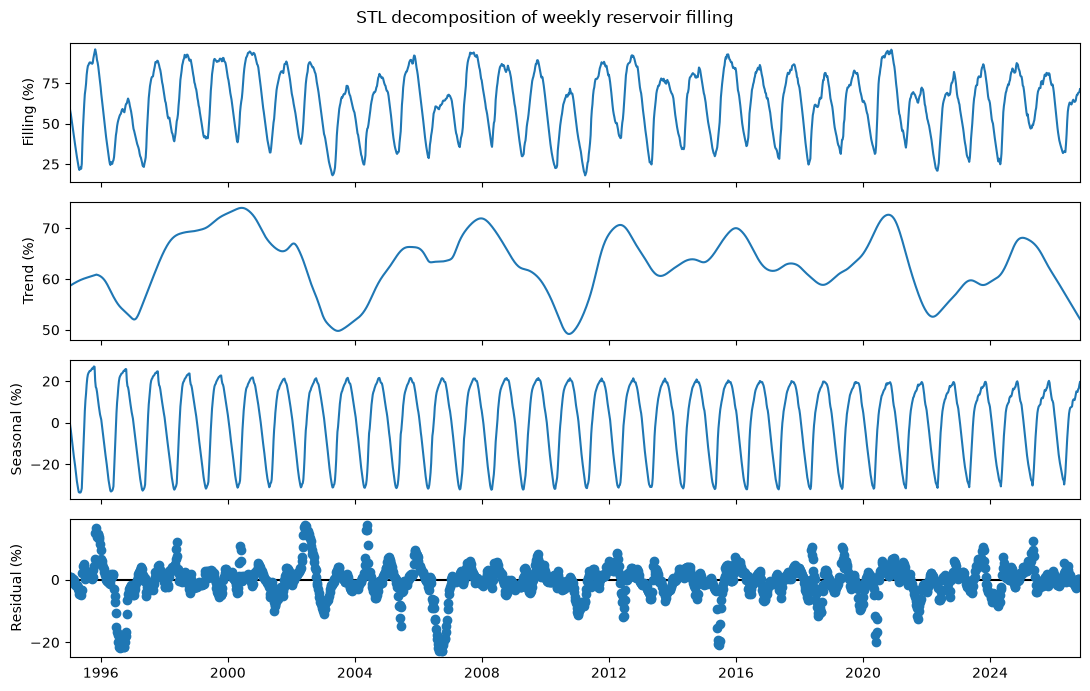

In [25]:
# Creating a plot_stl function to plot an STL decomposition of a weekly series
# Allowing for customization of the seasonal and trend smoother lengths, 
# as well as the option to use robust fitting.
def plot_stl(series, period=52, seasonal=13, trend=None, robust=True):
    """Plot an STL decomposition of a weekly series.

    series: weekly values with a time index and no gaps.
    period: number of samples per seasonal cycle.
    seasonal: seasonal smoother length in weeks, must be odd and at least 7.
    trend: trend smoother length, must be odd. None lets STL choose from the other settings.
    robust: reduces the influence of unusual weeks when True.
    Returns the figure.
    """

    # Defining a result variable to store the fitted STL decomposition
    result = STL(series, period=period, seasonal=seasonal, trend=trend, robust=robust).fit()
    # Creating the figure for plotting
    fig = result.plot()

    # Readable names with units
    names = ["Filling (%)", "Trend (%)", "Seasonal (%)", "Residual (%)"]

    # Removing the default "res_level" title and setting the new y-axis labels
    for ax, name in zip(fig.axes, names):
        ax.set_title("")      
        ax.set_ylabel(name)

    # Adding one title for the whole figure
    fig.suptitle("STL decomposition of weekly reservoir filling")
    # Setting the size of the figure to 11 inches by 7 inches for better visibility of the plots.
    fig.set_size_inches(11, 7)
    # Adjusting the layout of the figure to prevent overlap and ensure that the labels and titles are clearly visible.
    fig.tight_layout()
    # Returning the figure containing the STL decomposition plots.
    return fig

# Creating a figure by calling the plot_stl function 
fig = plot_stl(filling)
# Displaying the figure
plt.show()

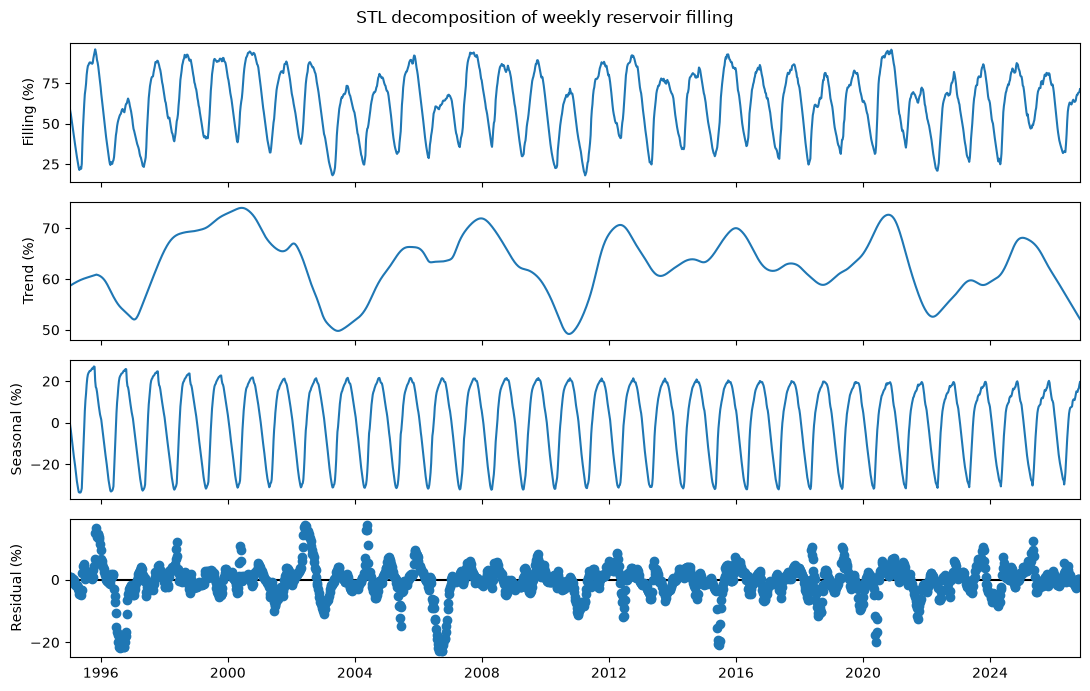

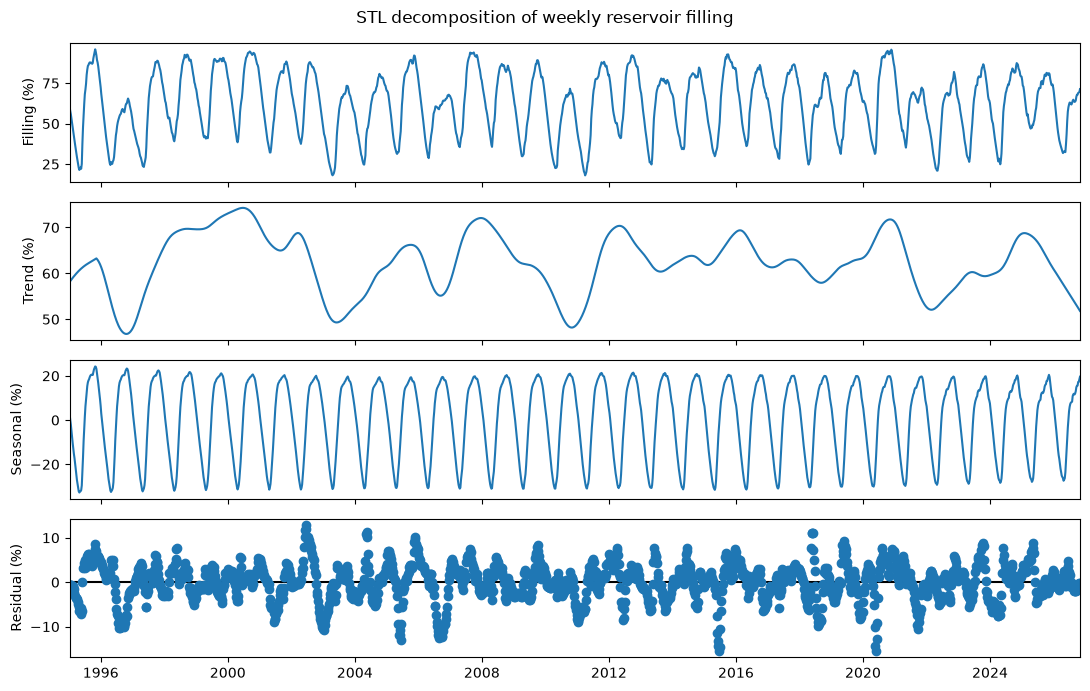

In [26]:
# Verifying that the number of axes in the STL decomposition plot is equal to 4, 
# which corresponds to the observed, trend, seasonal, and residual components.
assert len(plot_stl(filling).axes) == 4  # observed, trend, seasonal, residual
assert len(plot_stl(filling, robust=False).axes) == 4

# Trying to call the plot_stl function with a seasonal smoother length of 12, 
# Raising a ValueError if the seasonal parameter is not odd and at least 7, and catching the exception to ensure that the function behaves as expected.
try:
    plot_stl(filling, seasonal=12)
    raise AssertionError("seasonal=12 should fail, because it is an even number")

# Catching the ValueError raised by the plot_stl function when the seasonal parameter is not odd and at least 7
except ValueError:
    pass

#### Spectrogram

The spectrogram uses a 104-week window (two years), so each window contains two yearly
cycles, and the yearly cycle falls exactly on a frequency bin (resolution 0.5 cycles per year).
Neighbouring windows overlap by 78 weeks (75 %), so a new window starts every 26 weeks. The Hann
window gives little weight to the edges of each window, and the overlap makes sure every week
still counts fully. It also gives a smoother picture over time. 
(The arguing for this is written and explained by AI.)

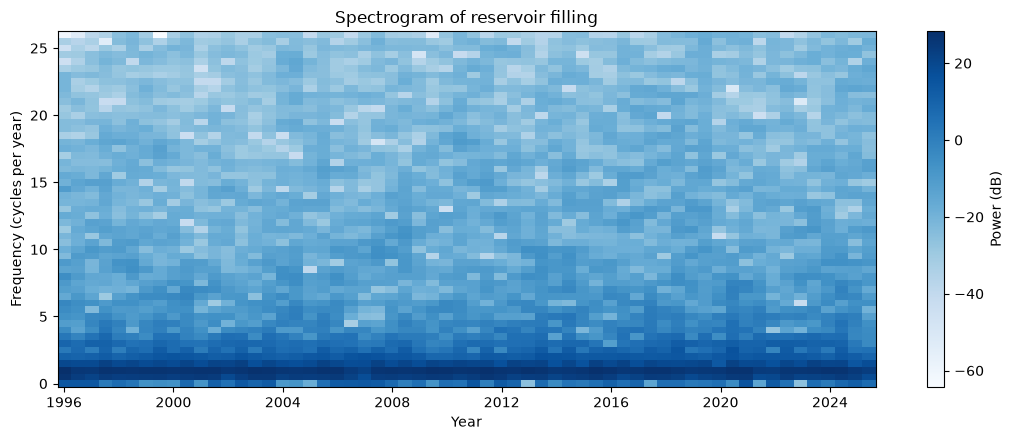

In [27]:
# Creating a plot_spectrogram function to plot a spectrogram of a weekly series,
# Allowing for customization of the window length and window overlap in weeks.
def plot_spectrogram(series, window_length=104, window_overlap=78):
    """Plot a spectrogram of a weekly series.

    series: weekly values with a time index and no gaps.
    window_length: number of weeks in each window.
    window_overlap: number of weeks shared by neighbouring windows.
    Returns the figure.
    """
    # Raising a value error if the window_overlap parameter is greater than or equal to the window_length parameter
    if window_overlap >= window_length:
        raise ValueError("window_overlap must be smaller than window_length")

    # Creating three variables to store the frequencies, times, and power of the spectrogram computed 
    # using the scipy.signal.spectrogram function.
    # fs=52 gives frequencies in cycles per year, since there are 52 samples per year
    frequencies, times, power = spectrogram(
        series.to_numpy(),
        fs=52,
        # Window type is set to "hann" for the Hann window, which is a commonly used window function in signal processing 
        # (Suggested by AI)
        window="hann",
        # The nperseg parameter specifies the number of samples per segment (window length) for the spectrogram computation,
        # and the noverlap parameter specifies the number of samples to overlap between segments (window
        nperseg=window_length,
        noverlap=window_overlap,
        # The detrend parameter is set to "linear" to remove any linear trend from the data before computing the spectrogram.
        detrend="linear",
    )
    # Defining a variable to store the window centers for plotting the spectrogram
    window_centers = series.index[0] + pd.to_timedelta(times * 52 * 7, unit="D")

    # Creating a figure and axes for plotting the spectrogram using matplotlib.pyplot.subplots
    fig, ax = plt.subplots(figsize=(11, 4.5))
    # Creating a pseudocolor plot of the spectrogram using the pcolormesh function (suggested by AI)
    mesh = ax.pcolormesh(window_centers, frequencies, 10 * np.log10(power + 1e-12), cmap="Blues", shading="auto")
    # Adding a colorbar to the plot to indicate the power in decibels (dB) for the spectrogram
    fig.colorbar(mesh, ax=ax, label="Power (dB)")
    # Setting the title, y-axis label, and x-axis label for the spectrogram plot 
    # to provide context and information about the data being visualized.
    ax.set_title(f"Spectrogram of reservoir filling")
    ax.set_ylabel("Frequency (cycles per year)")
    ax.set_xlabel("Year")
    # Adjusting the layout of the figure to prevent overlap and ensure that the labels and titles are clearly visible.
    fig.tight_layout()
    # Returning the figure containing the spectrogram plot.
    return fig

# Creating the figure by calling the plot_spectrogram function with the filling series
fig = plot_spectrogram(filling)
# Displaying the figure
plt.show()

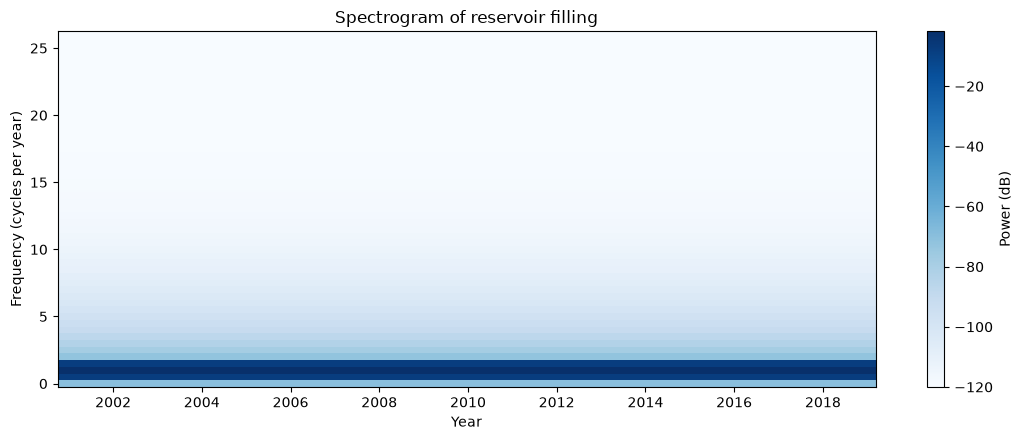

In [28]:
# Testing the plot_spectrogram function with a test series to ensure that it correctly identifies the peak frequency in the spectrogram.
weeks = np.arange(1040)
test_series = pd.Series(
    np.cos(2 * np.pi * weeks / 52),
    index=pd.date_range("2000-01-02", periods=len(weeks), freq="7D"),
)

# Creating a test figure by calling the plot_spectrogram function with the test series
test_fig = plot_spectrogram(test_series)

# Read the power values from the plotted spectrogram (one row per frequency bin).
power = np.asarray(test_fig.axes[0].collections[0].get_array()).reshape(53, -1)
# Average the power over time and find the frequency with the highest mean power.
peak_frequency = np.fft.rfftfreq(104, d=1 / 52)[power.mean(axis=1).argmax()]
# The strongest frequency should match the known frequency of the test signal.
assert peak_frequency == 1.0

# An overlap equal to the window length gives a step size of 0, so it must be rejected.
try:
    plot_spectrogram(test_series, window_length=104, window_overlap=104)
    raise AssertionError("Equal overlap should fail")

# Expected: the function rejected the invalid overlap.
except ValueError:
    pass

## Save locations for the Streamlit app

In [29]:
# Save the 5 grid cells with the most sampled points in each area for use in the app.
# Each area's top cells are tagged with the area name and combined into one table.
top_locations = pd.concat(
    load_locations(area).nlargest(5, "n_points").assign(area=area)
    for area in points["area"].unique()
)

top_locations.to_csv(DATA_DIR / "locations.csv", index=False, encoding="utf-8")

# Checking the result: each area should have 5 locations.
print(top_locations.groupby("area").size())

area
NO 1    5
NO 2    5
NO 3    5
NO 4    5
NO 5    5
RM      5
RN      5
RS      5
RV      5
RØ      5
dtype: int64


In [30]:
# HentOmråder lists VASS 1-4, so check which VASS area numbers actually have data.
print(magasin_data.query("area_type == 'VASS'")["area_nr"].unique())

# This was used during development to check which VASS areas really have data, 
# because the API’s area list doesn’t match the data itself 
# NVE’s HentOmråder endpoint lists VASS 1–4, but the reservoir data only contains VASS 1–3. 
# (All of this was noticed by Claude Opus 5.5)

[1 3 2]
